In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms, models

from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_curve
)

from PIL import Image
import warnings
warnings.filterwarnings("ignore")


In [ ]:
# 1. seed
def set_seed(seed=11):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(11)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 2. Paths & Transform
DATA_ROOT = os.environ.get("BISCUIT_DATA_DIR", "../../data/DS")  # built by 00_data_prep/prepare_data.py --mode ok_nok

trainPath = os.path.join(DATA_ROOT, 'train')
valPath   = os.path.join(DATA_ROOT, 'valid')
testPath  = os.path.join(DATA_ROOT, 'test')

print("DATA_ROOT:", DATA_ROOT)
print("Folders under DATA_ROOT:", os.listdir(DATA_ROOT))

IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# 3. SimpleImageDataset for train/ok (no class subfolders)
class SimpleImageDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform

        exts = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp')
        self.image_paths = [
            os.path.join(root_dir, f)
            for f in os.listdir(root_dir)
            if f.lower().endswith(exts)
        ]
        self.image_paths.sort()

        if len(self.image_paths) == 0:
            raise FileNotFoundError(f"No image files found in {root_dir}")

        # Mimic ImageFolder's interface to make debugging easier
        self.classes = ['ok']
        self.class_to_idx = {'ok': 0}
        self.samples = [(p, 0) for p in self.image_paths]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths[idx]
        img = Image.open(path).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, 0

Using device: cuda
DATA_ROOT: /content/drive/Shareddrives/CV_Project/Clustering/data/IndustryBiscuit/DS
Folders under DATA_ROOT: ['train', 'valid', 'test', 'resnet_features']


In [ ]:
# 4. Build Datasets & Dataloaders

# Training: use only train/ok as the normal class
train_ok_path = os.path.join(trainPath, 'ok')
train_dataset = SimpleImageDataset(root_dir=train_ok_path, transform=transform)

# Validation / test: standard ok + nok folder layout
val_dataset   = datasets.ImageFolder(root=valPath,   transform=transform)
test_dataset  = datasets.ImageFolder(root=testPath,  transform=transform)

print("Train image count:", len(train_dataset))
print("Val   classes:", val_dataset.classes, "class_to_idx:", val_dataset.class_to_idx)
print("Test  classes:", test_dataset.classes, "class_to_idx:", test_dataset.class_to_idx)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False, num_workers=2)


Train image count: 1000
Val   classes: ['nok', 'ok'] class_to_idx: {'nok': 0, 'ok': 1}
Test  classes: ['nok', 'ok'] class_to_idx: {'nok': 0, 'ok': 1}


In [ ]:
#  ResNet18 backbone (classification head removed; 512-d features only)

resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
resnet.fc = nn.Identity()    # drop the final fc layer, keep the 512-d features
resnet = resnet.to(device)
resnet.eval()
print(resnet)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 246MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
# 6. Feature Extraction Functions

@torch.no_grad()
def extract_features_unlabeled(model, loader, device):
    """for train/ok: no labels/paths needed"""
    all_feats = []
    model.eval()
    for x, _ in loader:
        x = x.to(device)
        feats = model(x)
        feats = feats.cpu().numpy()
        all_feats.append(feats)
    all_feats = np.concatenate(all_feats, axis=0)
    return all_feats

@torch.no_grad()
def extract_features_with_labels(model, loader, base_dataset, device):
    """
    for val/test: we want feats + labels + paths
    base_dataset must have .samples (ImageFolder)
    """
    all_feats = []
    all_labels = []
    all_paths = []

    model.eval()
    idx_offset = 0

    for x, y in loader:
        x = x.to(device)
        feats = model(x)
        feats = feats.cpu().numpy()
        all_feats.append(feats)
        all_labels.extend(y.cpu().numpy())

        bs = x.size(0)
        for i in range(bs):
            path, _ = base_dataset.samples[idx_offset + i]
            all_paths.append(path)
        idx_offset += bs

    all_feats  = np.concatenate(all_feats, axis=0)
    all_labels = np.array(all_labels)
    return all_feats, all_labels, all_paths

# Extract train / val / test features
train_feats = extract_features_unlabeled(resnet, train_loader, device)
val_feats,  val_labels,  val_paths  = extract_features_with_labels(resnet, val_loader,  val_dataset,  device)
test_feats, test_labels, test_paths = extract_features_with_labels(resnet, test_loader, test_dataset, device)

print("train_feats:", train_feats.shape)
print("val_feats:",   val_feats.shape,   np.unique(val_labels,   return_counts=True))
print("test_feats:",  test_feats.shape,  np.unique(test_labels,  return_counts=True))

# Get the ok/nok class indices from val_dataset
ok_idx  = val_dataset.class_to_idx['ok']
nok_idx = val_dataset.class_to_idx['nok']
print("ok_idx:", ok_idx, "nok_idx:", nok_idx)


train_feats: (1000, 512)
val_feats: (200, 512) (array([0, 1]), array([100, 100]))
test_feats: (200, 512) (array([0, 1]), array([100, 100]))
ok_idx: 1 nok_idx: 0


# Part 1. NOK Unsupervised Clustering
##    Separating the different defect types

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 200 samples in 0.007s...
[t-SNE] Computed neighbors for 200 samples in 0.109s...
[t-SNE] Computed conditional probabilities for sample 200 / 200
[t-SNE] Mean sigma: 4.764638
[t-SNE] KL divergence after 250 iterations with early exaggeration: 52.802746
[t-SNE] KL divergence after 1000 iterations: 0.355813


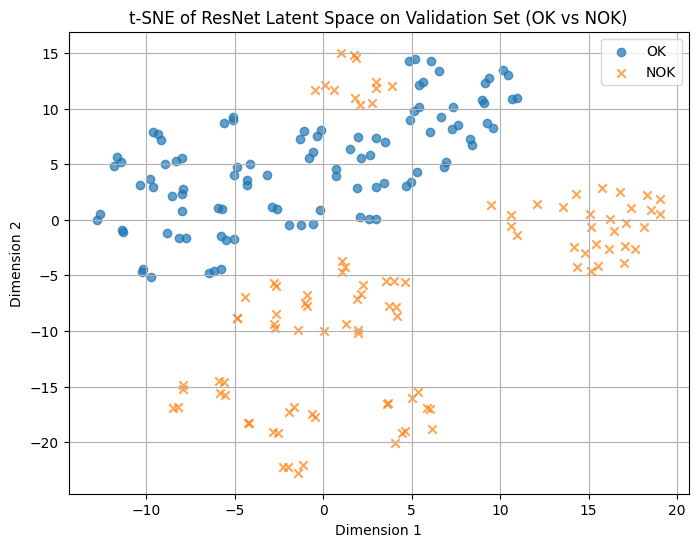

Total NOK samples: 200 feature dim: 512


In [ ]:
# 1.1 t-SNE on validation set (OK vs NOK)
pca_val = PCA(n_components=50, random_state=42)
val_feats_50 = pca_val.fit_transform(val_feats)

n_val = val_feats_50.shape[0]
perp_val = min(30, max(5, n_val // 3))

tsne_val = TSNE(
    n_components=2,
    random_state=42,
    perplexity=perp_val,
    init="pca",
    verbose=1,
)
val_2d = tsne_val.fit_transform(val_feats_50)

plt.figure(figsize=(8, 6))
for cls_idx, marker, color, name in [
    (ok_idx,  'o', 'tab:green', 'OK'),
    (nok_idx, 'x', 'tab:red',   'NOK'),
]:
    mask = (val_labels == cls_idx)
    plt.scatter(val_2d[mask, 0], val_2d[mask, 1],
                marker=marker, label=name, alpha=0.7)

plt.title("t-SNE of ResNet Latent Space on Validation Set (OK vs NOK)")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.legend()
plt.grid(True)
plt.show()

# 1.2 Gather all NOK features (val + test)
val_nok_mask  = (val_labels  == nok_idx)
test_nok_mask = (test_labels == nok_idx)

Z_nok = np.concatenate([
    val_feats[val_nok_mask],
    test_feats[test_nok_mask]
], axis=0)

nok_paths = [p for p, m in zip(val_paths,  val_nok_mask)  if m] + \
            [p for p, m in zip(test_paths, test_nok_mask) if m]

print("Total NOK samples:", Z_nok.shape[0], "feature dim:", Z_nok.shape[1])

Finding optimal K with Elbow Method on NOK features...


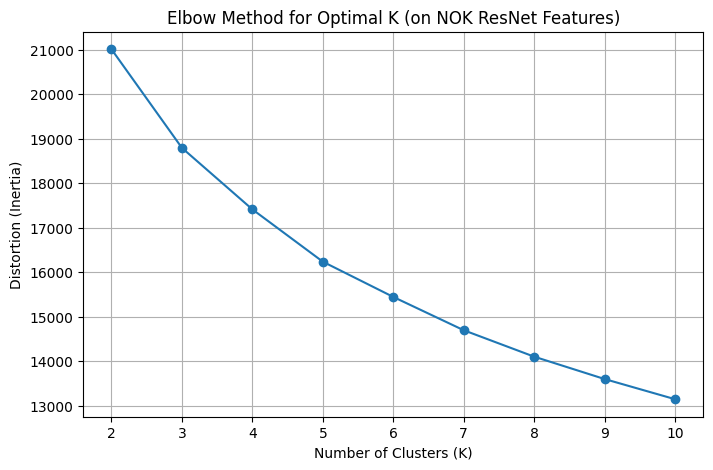

In [ ]:
# 1.3 Elbow Method
max_k = 10
K_range = range(2, max_k + 1)
distortions = []

print("Finding optimal K with Elbow Method on NOK features...")
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(Z_nok)
    distortions.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, distortions, marker='o')
plt.title('Elbow Method for Optimal K (on NOK ResNet Features)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Distortion (Inertia)')
plt.grid(True)
plt.show()

Cluster counts (cluster_id, count): (array([0, 1, 2, 3, 4], dtype=int32), array([54, 28, 66, 24, 28]))
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 200 samples in 0.003s...
[t-SNE] Computed neighbors for 200 samples in 0.065s...
[t-SNE] Computed conditional probabilities for sample 200 / 200
[t-SNE] Mean sigma: 5.052632
[t-SNE] KL divergence after 250 iterations with early exaggeration: 52.422058
[t-SNE] KL divergence after 1000 iterations: 0.319530


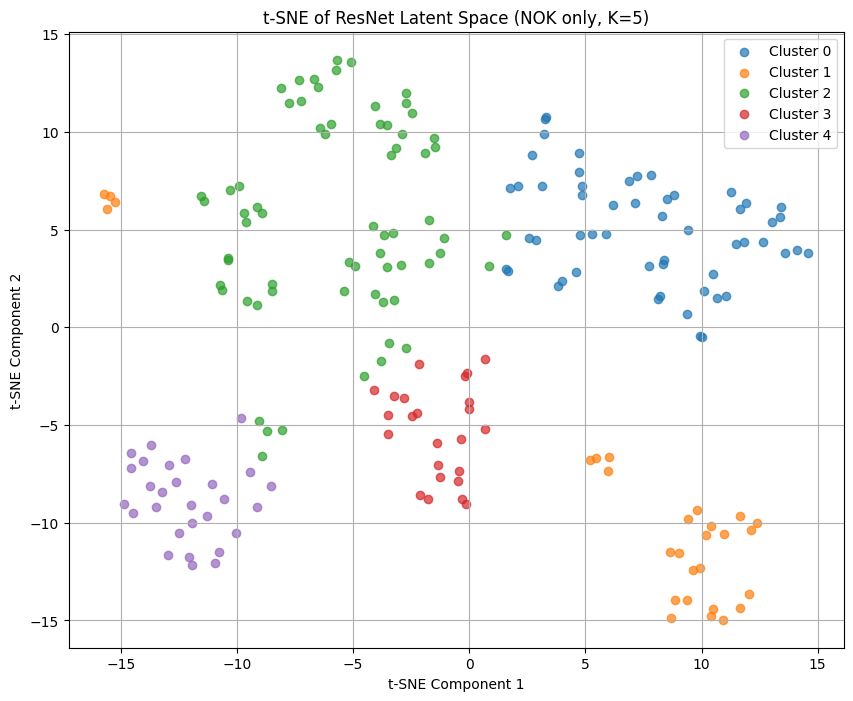

In [ ]:
# 1.4  KMeans + t-SNE
K_FINAL = 5

kmeans_nok = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
cluster_labels = kmeans_nok.fit_predict(Z_nok)

print("Cluster counts (cluster_id, count):", np.unique(cluster_labels, return_counts=True))

pca_nok = PCA(n_components=30, random_state=42)
Z_nok_30 = pca_nok.fit_transform(Z_nok)

n_nok = Z_nok_30.shape[0]
perp_nok = min(30, max(5, n_nok // 3))

tsne_nok = TSNE(
    n_components=2,
    random_state=42,
    perplexity=perp_nok,
    init="pca",
    verbose=1,
)
Z_nok_2d = tsne_nok.fit_transform(Z_nok_30)

plt.figure(figsize=(10, 8))
for cid in range(K_FINAL):
    mask = (cluster_labels == cid)
    plt.scatter(Z_nok_2d[mask, 0], Z_nok_2d[mask, 1],
                label=f"Cluster {cid}", alpha=0.7)
plt.title(f"t-SNE of ResNet Latent Space (NOK only, K={K_FINAL})")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend()
plt.grid(True)
plt.show()

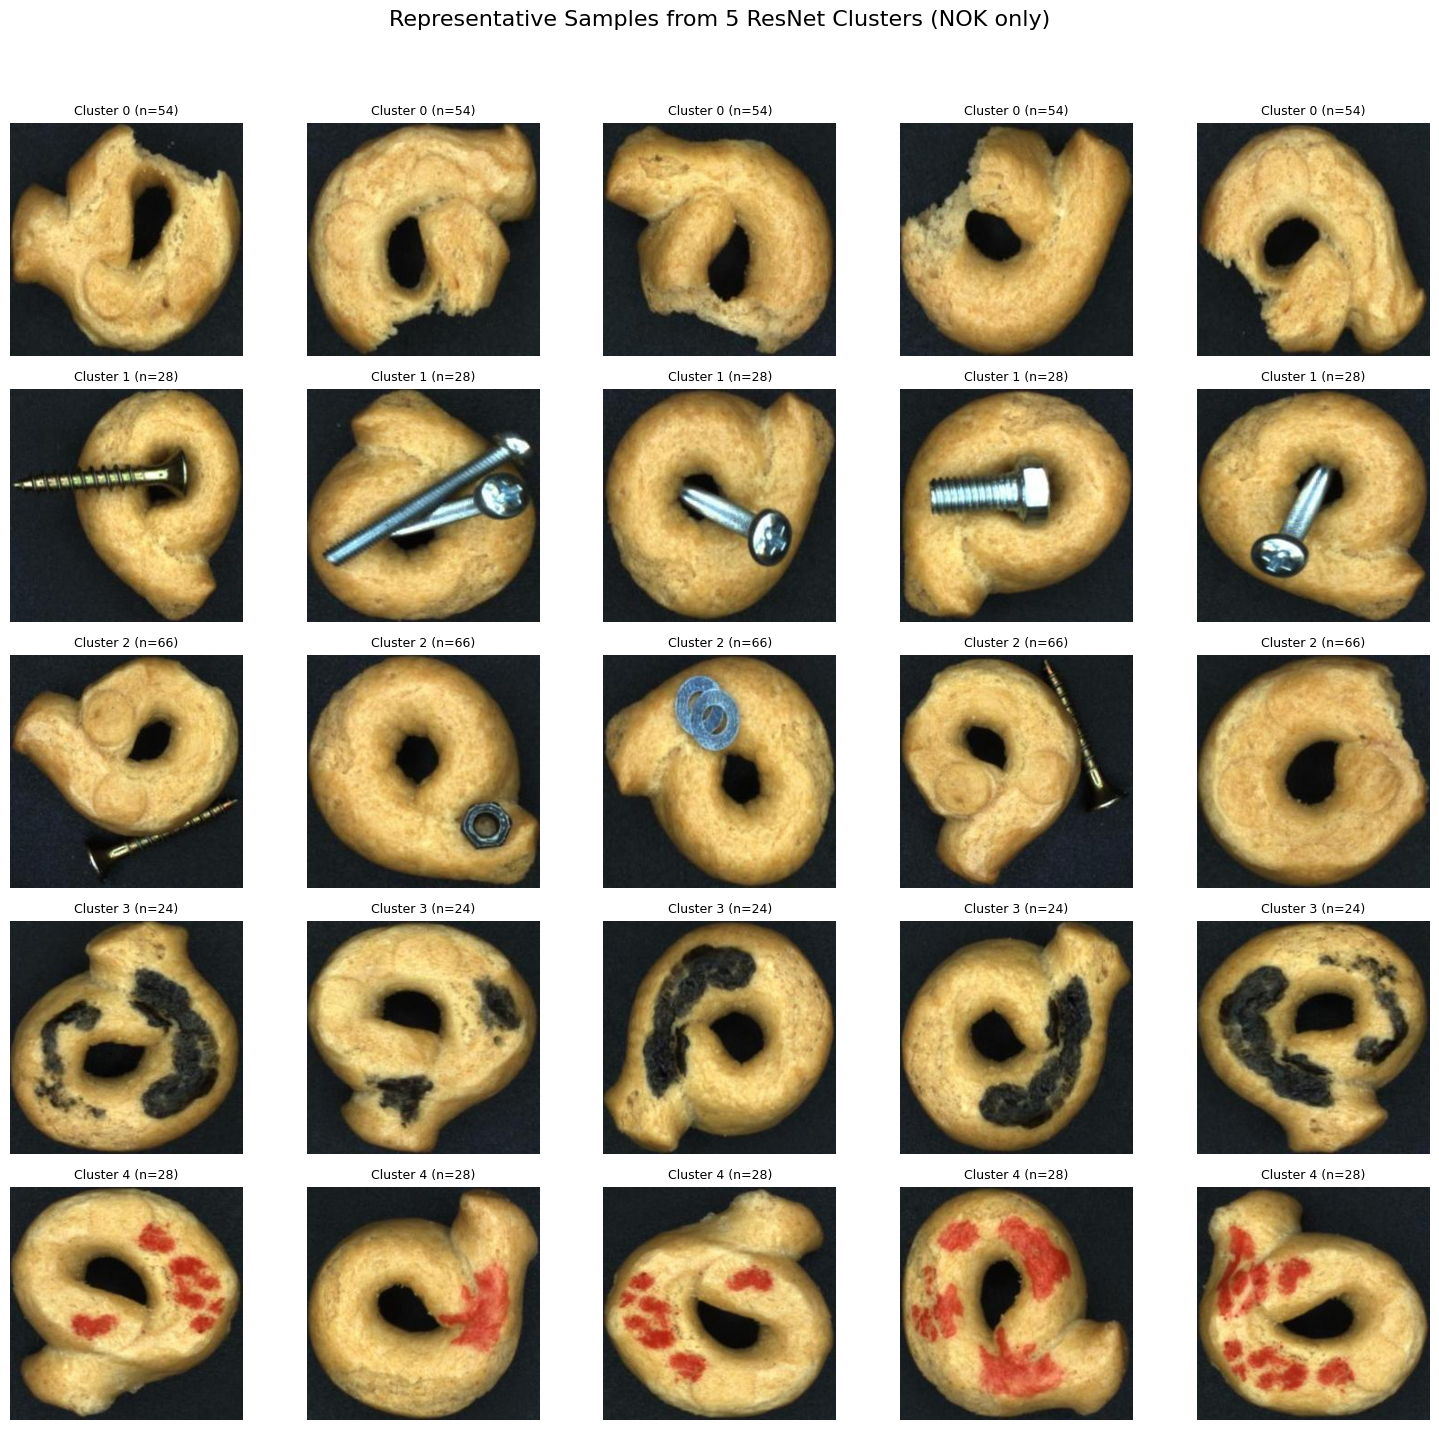

In [ ]:
# 1.5 Visualize representative samples from each cluster
def plot_cluster_samples(nok_paths, cluster_labels, k_final, samples_per_cluster=5):
    fig, axes = plt.subplots(k_final, samples_per_cluster,
                             figsize=(3 * samples_per_cluster, 3 * k_final))
    fig.suptitle(f"Representative Samples from {k_final} ResNet Clusters (NOK only)",
                 fontsize=16)

    if k_final == 1:
        axes = np.expand_dims(axes, axis=0)

    for cluster_id in range(k_final):
        indices = np.where(cluster_labels == cluster_id)[0]
        if len(indices) == 0:
            print(f"Cluster {cluster_id} is empty.")
            continue

        n_show = min(samples_per_cluster, len(indices))
        sample_indices = np.random.choice(indices, n_show, replace=False)

        for i, idx in enumerate(sample_indices):
            img_path = nok_paths[idx]
            ax = axes[cluster_id, i]
            try:
                img = Image.open(img_path).convert("RGB")
                ax.imshow(img)
                ax.set_title(f"Cluster {cluster_id} (n={len(indices)})", fontsize=9)
                ax.axis('off')
            except Exception:
                ax.axis('off')
                continue

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

plot_cluster_samples(nok_paths, cluster_labels, K_FINAL, samples_per_cluster=5)


#Part 2. One-Class Learning on Normal (OK) for Anomaly Detection
##    Goal: train a one-class model on OK samples only, then flag NOK automatically at test time

In [ ]:
train_ok_feats = train_feats

# val: OK + NOK for hyperparameter tuning & early evaluation
val_ok_feats  = val_feats[val_labels == ok_idx]
val_nok_feats = val_feats[val_labels == nok_idx]

# test: OK + NOK for the final evaluation
test_ok_feats  = test_feats[test_labels == ok_idx]
test_nok_feats = test_feats[test_labels == nok_idx]

print("train_ok_feats:", train_ok_feats.shape)
print("val_ok_feats:",  val_ok_feats.shape, "val_nok_feats:",  val_nok_feats.shape)
print("test_ok_feats:", test_ok_feats.shape, "test_nok_feats:", test_nok_feats.shape)

val_paths = np.array(val_paths)
test_paths = np.array(test_paths)

# Fit on train_ok only
scaler = StandardScaler()
train_ok_scaled = scaler.fit_transform(train_ok_feats)

val_ok_scaled   = scaler.transform(val_ok_feats)
val_nok_scaled  = scaler.transform(val_nok_feats)

test_ok_scaled  = scaler.transform(test_ok_feats)
test_nok_scaled = scaler.transform(test_nok_feats)

train_ok_feats: (1000, 512)
val_ok_feats: (100, 512) val_nok_feats: (100, 512)
test_ok_feats: (100, 512) test_nok_feats: (100, 512)


In [ ]:
# OCSVM hyperparameter search on the validation set
def eval_ocsvm_on_val(nu, gamma):
    """
    Train an OCSVM with the given (nu, gamma) on train_ok only,
    and evaluate AUC and F1 on val_ok / val_nok.
    """
    oc = OneClassSVM(kernel='rbf', nu=nu, gamma=gamma)
    oc.fit(train_ok_scaled)

    # decision_function: more positive = more normal, more negative = more abnormal
    ok_scores  = oc.decision_function(val_ok_scaled)
    nok_scores = oc.decision_function(val_nok_scaled)

    # y_true: 0=normal, 1=anomaly
    y_true = np.concatenate([
        np.zeros_like(ok_scores),   # OK
        np.ones_like(nok_scores),   # NOK
    ])
    # y_scores: higher = more anomalous
    y_scores = np.concatenate([
        -ok_scores,
        -nok_scores,
    ])

    auc = roc_auc_score(y_true, y_scores)

    # Hard decision with oc.predict: +1 = normal, -1 = anomaly
    ok_pred  = oc.predict(val_ok_scaled)
    nok_pred = oc.predict(val_nok_scaled)
    y_pred = np.concatenate([ok_pred, nok_pred])
    y_pred = (y_pred == -1).astype(int)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='binary', pos_label=1
    )

    return auc, f1, precision, recall, oc

nu_list    = [0.01, 0.05, 0.1]
gamma_list = ['scale', 0.001, 0.01, 0.1]

results = []
best_model = None
best_auc = -1.0
best_f1  = -1.0
best_cfg = None

print("Grid search on validation set...")
for nu in nu_list:
    for gamma in gamma_list:
        auc, f1, prec, rec, oc = eval_ocsvm_on_val(nu, gamma)
        results.append((nu, gamma, auc, f1, prec, rec))
        print(f"nu={nu}, gamma={gamma} -> val AUC={auc:.4f}, F1={f1:.4f}, "
              f"P={prec:.4f}, R={rec:.4f}")

        score = 0.7 * auc + 0.3 * f1
        if score > (0.7 * best_auc + 0.3 * best_f1):
            best_auc = auc
            best_f1  = f1
            best_model = oc
            best_cfg = (nu, gamma)

print("\nBest hyperparams on val:")
print(f"  nu={best_cfg[0]}, gamma={best_cfg[1]}")
print(f"  val AUC={best_auc:.4f}, F1={best_f1:.4f}")

ocsvm_best = best_model


Grid search on validation set...
nu=0.01, gamma=scale -> val AUC=0.9766, F1=0.8837, P=0.8261, R=0.9500
nu=0.01, gamma=0.001 -> val AUC=0.9750, F1=0.8945, P=0.8990, R=0.8900
nu=0.01, gamma=0.01 -> val AUC=0.9779, F1=0.6667, P=0.5000, R=1.0000
nu=0.01, gamma=0.1 -> val AUC=0.6850, F1=0.6667, P=0.5000, R=1.0000
nu=0.05, gamma=scale -> val AUC=0.9772, F1=0.8796, P=0.8190, R=0.9500
nu=0.05, gamma=0.001 -> val AUC=0.9761, F1=0.9020, P=0.8846, R=0.9200
nu=0.05, gamma=0.01 -> val AUC=0.9776, F1=0.6667, P=0.5000, R=1.0000
nu=0.05, gamma=0.1 -> val AUC=0.6850, F1=0.6667, P=0.5000, R=1.0000
nu=0.1, gamma=scale -> val AUC=0.9767, F1=0.8778, P=0.8017, R=0.9700
nu=0.1, gamma=0.001 -> val AUC=0.9729, F1=0.8796, P=0.8190, R=0.9500
nu=0.1, gamma=0.01 -> val AUC=0.9776, F1=0.6667, P=0.5000, R=1.0000
nu=0.1, gamma=0.1 -> val AUC=0.6850, F1=0.6667, P=0.5000, R=1.0000

Best hyperparams on val:
  nu=0.05, gamma=0.001
  val AUC=0.9761, F1=0.9020


In [ ]:
# 1) Predict on the full validation set (OK + NOK) with the best OCSVM
val_feats_scaled_all = scaler.transform(val_feats)
val_pred_all   = ocsvm_best.predict(val_feats_scaled_all)      # +1=normal, -1=anomaly
val_scores_all = ocsvm_best.decision_function(val_feats_scaled_all)

anom_mask      = (val_pred_all == -1)
anom_feats     = val_feats_scaled_all[anom_mask]
anom_labels    = val_labels[anom_mask]
anom_paths     = val_paths[anom_mask]

print(f"\n[Val anomaly clustering] Validation samples flagged as anomalous: "
      f"{anom_feats.shape[0]} / {val_feats.shape[0]}")

# 2) PCA
if anom_feats.shape[0] >= 5:
    n_components = min(30, anom_feats.shape[0], anom_feats.shape[1])
    pca_anom = PCA(n_components=n_components, random_state=42)
    anom_pca = pca_anom.fit_transform(anom_feats)
    print("Anomaly PCA shape:", anom_pca.shape)
else:
    print("Too few validation samples flagged as anomalous; skipping clustering and visualization.")



[Val anomaly clustering] Validation 中被判为异常的样本数: 104 / 200
Anomaly PCA shape: (104, 30)


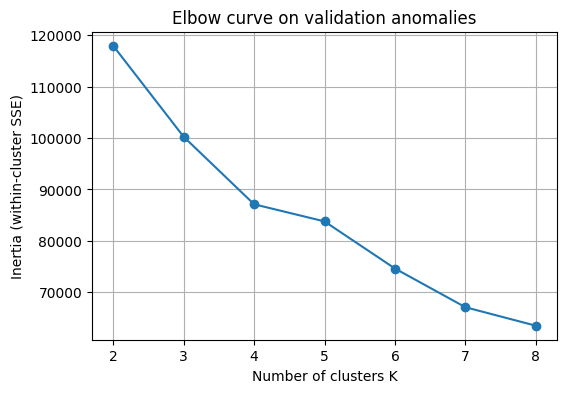

In [ ]:
# Elbow plot on anom_pca

if 'anom_pca' in globals() and anom_pca.shape[0] >= 5:
    K_range = range(2, 9)
    inertias = []
    for k in K_range:
        km = KMeans(n_clusters=k, random_state=42)
        km.fit(anom_pca)
        inertias.append(km.inertia_)

    plt.figure(figsize=(6, 4))
    plt.plot(K_range, inertias, marker='o')
    plt.xlabel("Number of clusters K")
    plt.ylabel("Inertia (within-cluster SSE)")
    plt.title("Elbow curve on validation anomalies")
    plt.grid(True)
    plt.show()
else:
    print("anom_pca is missing or there are too few anomalies; cannot draw the elbow curve.")


[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 104 samples in 0.000s...
[t-SNE] Computed neighbors for 104 samples in 0.002s...
[t-SNE] Computed conditional probabilities for sample 104 / 104
[t-SNE] Mean sigma: 20.089746
[t-SNE] KL divergence after 250 iterations with early exaggeration: 49.482246
[t-SNE] KL divergence after 900 iterations: 0.149814


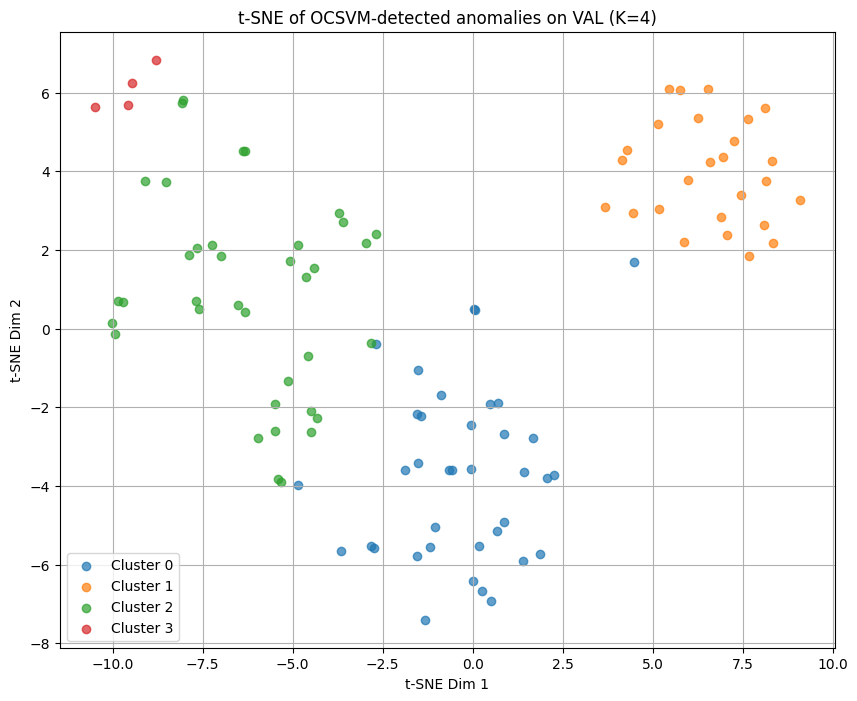

In [ ]:
# KMeans clustering + t-SNE
if 'anom_pca' in globals() and anom_pca.shape[0] >= 5:
    K_FINAL_ANOM = 4

    # 1) Final KMeans
    kmeans_anom = KMeans(n_clusters=K_FINAL_ANOM, random_state=42)
    cluster_labels_anom = kmeans_anom.fit_predict(anom_pca)

    # 2) t-SNE
    anom_30 = anom_pca
    perp_anom = min(30, max(5, anom_30.shape[0] // 3))
    tsne_anom = TSNE(
        n_components=2,
        random_state=42,
        perplexity=perp_anom,
        init="pca",
        verbose=1,
    )
    anom_2d = tsne_anom.fit_transform(anom_30)

    plt.figure(figsize=(10, 8))
    for cid in range(K_FINAL_ANOM):
        mask = (cluster_labels_anom == cid)
        plt.scatter(anom_2d[mask, 0], anom_2d[mask, 1],
                    alpha=0.7, label=f"Cluster {cid}")
    plt.title(f"t-SNE of OCSVM-detected anomalies on VAL (K={K_FINAL_ANOM})")
    plt.xlabel("t-SNE Dim 1")
    plt.ylabel("t-SNE Dim 2")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("anom_pca is missing or there are too few anomalies; cannot run KMeans + t-SNE.")



[Stats] Cluster × (OK/NOK) on validation anomalies:
 cluster  total  ok_in_cluster  nok_in_cluster  nok_ratio
       0     37              8              29   0.783784
       1     26              0              26   1.000000
       2     37              4              33   0.891892
       3      4              0               4   1.000000


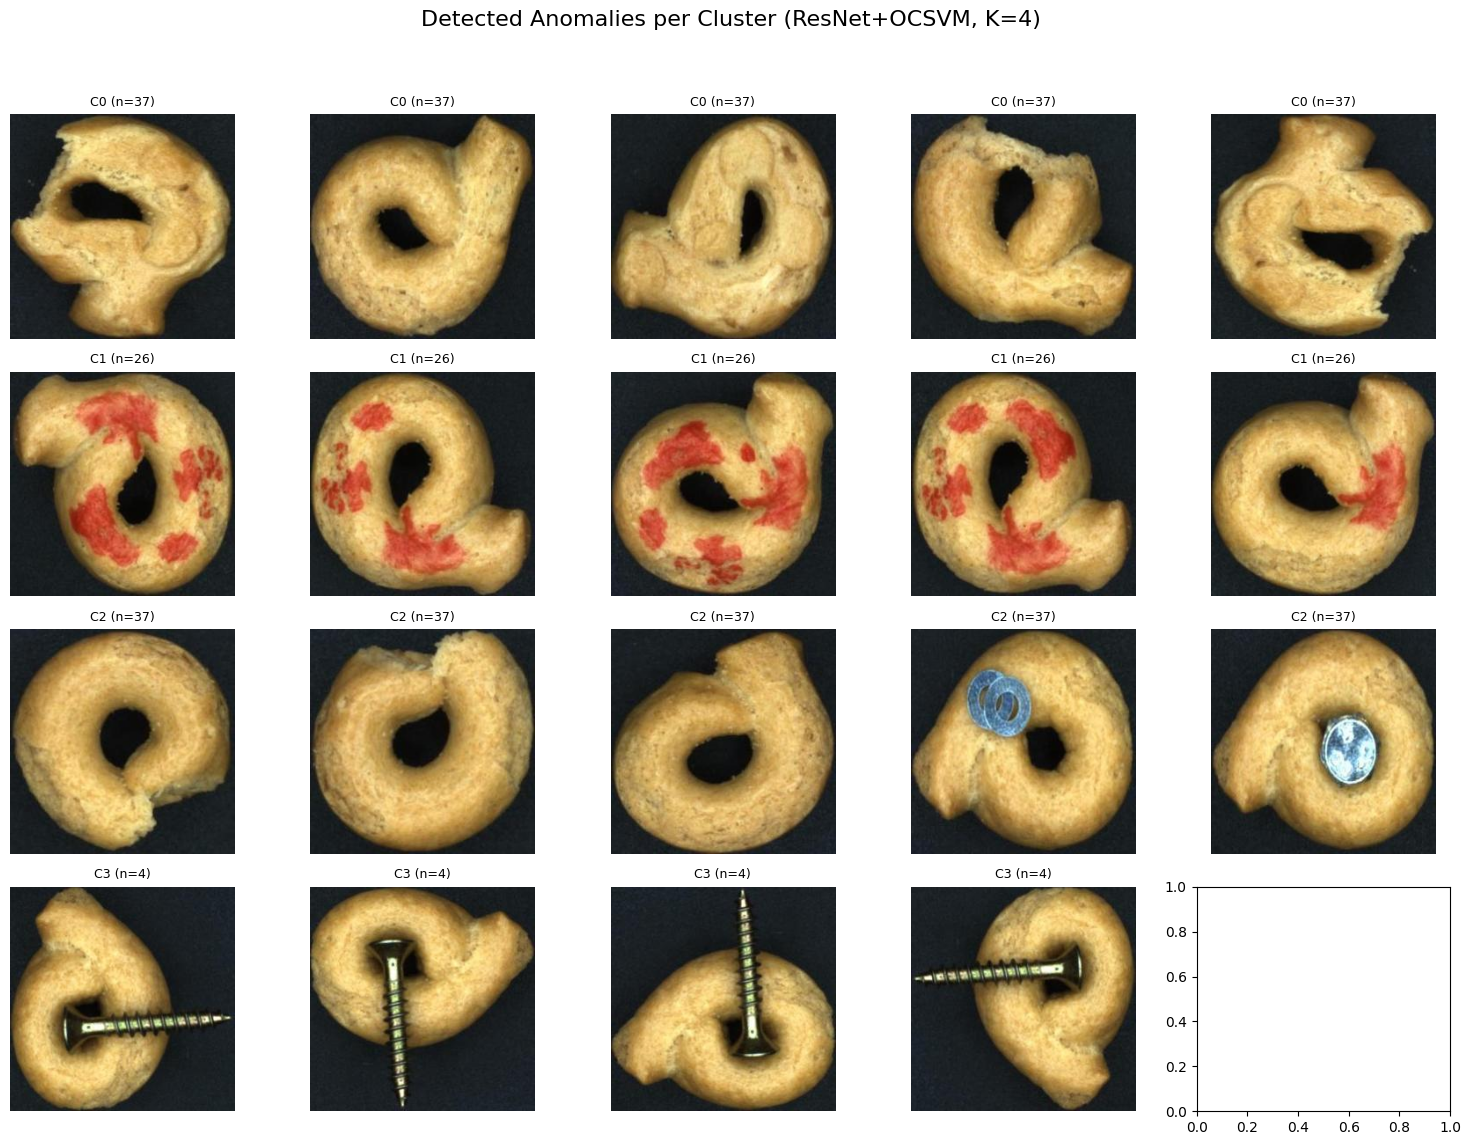


[Confusion-style] cluster × true OK/NOK on validation anomalies:
true_label  OK  NOK
cluster            
0            8   29
1            0   26
2            4   33
3            0    4


In [ ]:
# Sample images from each anomaly cluster
if ('cluster_labels_anom' in globals()
    and 'anom_feats' in globals()
    and anom_feats.shape[0] >= 5):

    # 1) OK / NOK breakdown per cluster
    cluster_stats = []
    for cid in range(K_FINAL_ANOM):
        mask_c = (cluster_labels_anom == cid)
        total_c = mask_c.sum()
        if total_c == 0:
            ok_c = 0
            nok_c = 0
        else:
            ok_c  = np.sum(anom_labels[mask_c] == ok_idx)
            nok_c = np.sum(anom_labels[mask_c] == nok_idx)
        cluster_stats.append({
            "cluster": cid,
            "total": total_c,
            "ok_in_cluster": ok_c,
            "nok_in_cluster": nok_c,
            "nok_ratio": nok_c / total_c if total_c > 0 else 0.0
        })

    cluster_df = pd.DataFrame(cluster_stats)
    print("\n[Stats] Cluster × (OK/NOK) on validation anomalies:")
    print(cluster_df.to_string(index=False))

    # 2) Show a few anomaly images from each cluster
    def plot_detected_anomaly_clusters(anom_paths, cluster_labels, k_final, samples_per_cluster=5):
        fig, axes = plt.subplots(k_final, samples_per_cluster,
                                 figsize=(3 * samples_per_cluster, 3 * k_final))
        fig.suptitle(f"Detected Anomalies per Cluster (ResNet+OCSVM, K={k_final})",
                     fontsize=16)

        if k_final == 1:
            axes = np.expand_dims(axes, axis=0)

        for cid in range(k_final):
            indices = np.where(cluster_labels == cid)[0]
            if len(indices) == 0:
                print(f"Cluster {cid} is empty.")
                continue

            n_show = min(samples_per_cluster, len(indices))
            sample_indices = np.random.choice(indices, n_show, replace=False)

            for i, idx in enumerate(sample_indices):
                path = anom_paths[idx]
                ax = axes[cid, i]
                try:
                    img = Image.open(path).convert("RGB")
                    ax.imshow(img)
                    ax.set_title(f"C{cid} (n={len(indices)})", fontsize=9)
                    ax.axis('off')
                except Exception:
                    ax.axis('off')
                    continue

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

    plot_detected_anomaly_clusters(anom_paths, cluster_labels_anom,
                                   K_FINAL_ANOM, samples_per_cluster=5)

    # 3) Treat cluster as the 'prediction' and OK/NOK as ground truth; build a confusion-style matrix
    true_label_str = np.where(anom_labels == nok_idx, "NOK", "OK")

    cm_cluster = pd.crosstab(
        cluster_labels_anom,
        true_label_str,
        rownames=["cluster"],
        colnames=["true_label"],
        dropna=False
    )

    for col in ["OK", "NOK"]:
        if col not in cm_cluster.columns:
            cm_cluster[col] = 0
    cm_cluster = cm_cluster[["OK", "NOK"]]

    print("\n[Confusion-style] cluster × true OK/NOK on validation anomalies:")
    print(cm_cluster.to_string())
else:
    print("cluster_labels_anom is missing or there are too few anomalies; skipping stats and image display.")



Test ROC-AUC: 0.9333


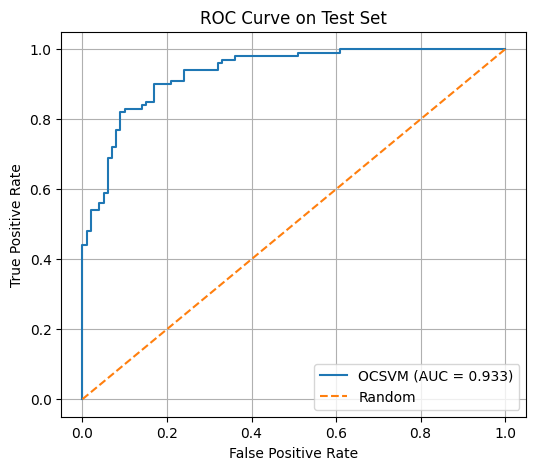


Confusion Matrix on TEST:
          Pred OK  Pred NOK
True OK        91         9
True NOK       20        80


In [ ]:
# Evaluate the OCSVM on TEST: ROC + confusion matrix
from sklearn.metrics import confusion_matrix, roc_curve, auc, roc_auc_score, precision_recall_fscore_support

ocsvm = ocsvm_best

# 1) Compute scores
ok_scores_test  = ocsvm.decision_function(test_ok_scaled)
nok_scores_test = ocsvm.decision_function(test_nok_scaled)

y_true_test = np.concatenate([
    np.zeros_like(ok_scores_test),   # 0 = normal (OK)
    np.ones_like(nok_scores_test),   # 1 = anomaly (NOK)
])
y_scores_test = np.concatenate([
    -ok_scores_test,   # negate so that higher = more anomalous
    -nok_scores_test,
])

# 2) ROC & AUC
test_auc = roc_auc_score(y_true_test, y_scores_test)
print(f"\nTest ROC-AUC: {test_auc:.4f}")

fpr, tpr, thresholds = roc_curve(y_true_test, y_scores_test)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'OCSVM (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve on Test Set')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# 3) Confusion matrix + Precision / Recall / F1
ok_pred_test  = ocsvm.predict(test_ok_scaled)
nok_pred_test = ocsvm.predict(test_nok_scaled)

y_pred_test = np.concatenate([ok_pred_test, nok_pred_test])
y_pred_test = (y_pred_test == -1).astype(int)  # 1 = anomaly

cm = confusion_matrix(y_true_test, y_pred_test)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true_test, y_pred_test, average='binary', pos_label=1
)

tn, fp, fn, tp = cm.ravel()

cm_2x2 = pd.DataFrame(
    [[tn, fp],
     [fn, tp]],
    index=["True OK", "True NOK"],
    columns=["Pred OK", "Pred NOK"]
)

print("\nConfusion Matrix on TEST:")
print(cm_2x2)


[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 200 samples in 0.004s...
[t-SNE] Computed neighbors for 200 samples in 0.054s...
[t-SNE] Computed conditional probabilities for sample 200 / 200
[t-SNE] Mean sigma: 4.343995
[t-SNE] KL divergence after 250 iterations with early exaggeration: 52.992767
[t-SNE] KL divergence after 950 iterations: 0.464104


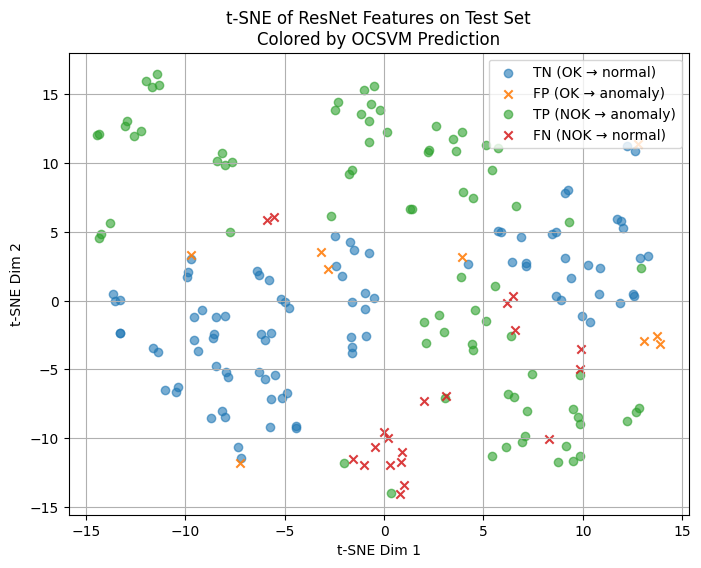

In [ ]:
# t-SNE (TN/FP/TP/FN)
# t-SNE visualization of TEST (TN/FP/TP/FN)
all_test_feats  = np.concatenate([test_ok_feats, test_nok_feats], axis=0)
all_test_labels = np.concatenate([
    np.zeros(test_ok_feats.shape[0]),  # 0 = OK
    np.ones(test_nok_feats.shape[0]),  # 1 = NOK
])

pca_test = PCA(n_components=30, random_state=42)
all_test_30 = pca_test.fit_transform(all_test_feats)

n_test = all_test_30.shape[0]
perp_test = min(30, max(5, n_test // 3))

tsne_test = TSNE(
    n_components=2,
    random_state=42,
    perplexity=perp_test,
    init="pca",
    verbose=1,
)
all_test_2d = tsne_test.fit_transform(all_test_30)

y_true = y_true_test
all_test_pred = y_pred_test  # 1 = anomaly, 0 = normal

TN_mask = (y_true == 0) & (all_test_pred == 0)
FP_mask = (y_true == 0) & (all_test_pred == 1)
TP_mask = (y_true == 1) & (all_test_pred == 1)
FN_mask = (y_true == 1) & (all_test_pred == 0)

plt.figure(figsize=(8, 6))
plt.scatter(all_test_2d[TN_mask, 0], all_test_2d[TN_mask, 1],
            alpha=0.6, label='TN (OK → normal)')
plt.scatter(all_test_2d[FP_mask, 0], all_test_2d[FP_mask, 1],
            alpha=0.9, marker='x', label='FP (OK → anomaly)')
plt.scatter(all_test_2d[TP_mask, 0], all_test_2d[TP_mask, 1],
            alpha=0.6, label='TP (NOK → anomaly)')
plt.scatter(all_test_2d[FN_mask, 0], all_test_2d[FN_mask, 1],
            alpha=0.9, marker='x', label='FN (NOK → normal)')

plt.title("t-SNE of ResNet Features on Test Set\nColored by OCSVM Prediction")
plt.xlabel("t-SNE Dim 1")
plt.ylabel("t-SNE Dim 2")
plt.legend()
plt.grid(True)
plt.show()



# Training the OCSVM on all OK + NOK images

In [ ]:
import os, glob
import numpy as np

DATA_ROOT = os.environ.get("BISCUIT_DATA_DIR", "../../data/DS")  # built by 00_data_prep/prepare_data.py --mode ok_nok

TEST_OK_DIR  = os.path.join(DATA_ROOT, "test", "ok")
TEST_NOK_DIR = os.path.join(DATA_ROOT, "test", "nok")

print("TEST_OK_DIR :", TEST_OK_DIR)
print("TEST_NOK_DIR:", TEST_NOK_DIR)

test_ok_paths  = sorted(glob.glob(os.path.join(TEST_OK_DIR, "*")))
test_nok_paths = sorted(glob.glob(os.path.join(TEST_NOK_DIR, "*")))

print("len(test_ok_paths)  =", len(test_ok_paths))
print("len(test_nok_paths) =", len(test_nok_paths))


TEST_OK_DIR : /content/drive/Shareddrives/CV_Project/Clustering/data/IndustryBiscuit/DS/test/ok
TEST_NOK_DIR: /content/drive/Shareddrives/CV_Project/Clustering/data/IndustryBiscuit/DS/test/nok
len(test_ok_paths)  = 100
len(test_nok_paths) = 100


X_train_all shape: (1200, 512)
Trained OCSVM on ALL (OK+NOK) with nu=0.05, gamma=0.001
VAL: (200, 512) TEST: (200, 512)

Best threshold on VAL:
threshold    1.088963
precision    0.804124
recall       0.780000
f1           0.791878
Name: 19, dtype: float64

Confusion matrix (TEST, tuned threshold):
[[83 17]
 [28 72]]

Classification report (TEST, tuned threshold):
              precision    recall  f1-score   support

          OK       0.75      0.83      0.79       100
         NOK       0.81      0.72      0.76       100

    accuracy                           0.78       200
   macro avg       0.78      0.77      0.77       200
weighted avg       0.78      0.78      0.77       200


Counts on TEST:
TN (OK→OK): 83
FP (OK→NOK): 17
FN (NOK→OK): 28
TP (NOK→NOK): 72

Average decision_function score on TEST:
TN (OK→OK): n=83, mean_score=2.256
FP (OK→NOK): n=17, mean_score=0.350
FN (NOK→OK): n=28, mean_score=1.715
TP (NOK→NOK): n=72, mean_score=-1.969

len(test_paths_all) = 200


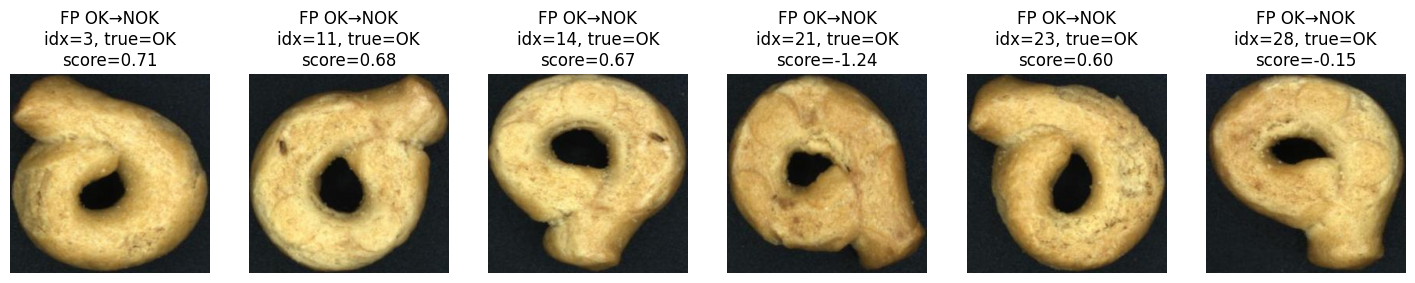

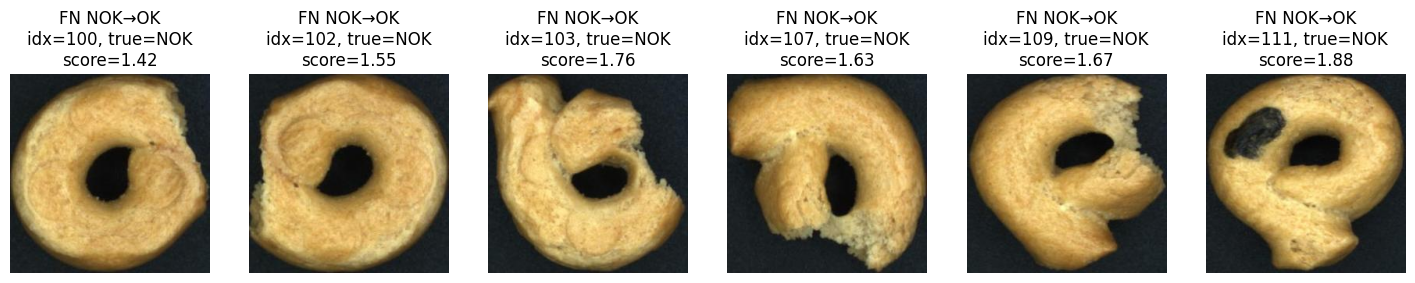

In [ ]:
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

def ocsvm_predict(ocsvm, scaler, X, threshold=0.0):
    X_scaled = scaler.transform(X)
    scores = ocsvm.decision_function(X_scaled)
    y_pred = (scores < threshold).astype(int)
    return y_pred, scores


# 1. train OCSVM in ok/nok
X_train_all = np.concatenate(
    [train_ok_feats, val_ok_feats, val_nok_feats],
    axis=0
)
print("X_train_all shape:", X_train_all.shape)

scaler_all = StandardScaler()
X_train_all_scaled = scaler_all.fit_transform(X_train_all)

nu_best, gamma_best = 0.05, 0.001
ocsvm_all = OneClassSVM(kernel="rbf", nu=nu_best, gamma=gamma_best)
ocsvm_all.fit(X_train_all_scaled)
print(f"Trained OCSVM on ALL (OK+NOK) with nu={nu_best}, gamma={gamma_best}")


# 2. construct  VAL / TEST feature and label
X_val_all = np.concatenate([val_ok_feats, val_nok_feats], axis=0)
y_val_true = np.concatenate([
    np.zeros(val_ok_feats.shape[0], dtype=int),  # 0 = OK
    np.ones(val_nok_feats.shape[0], dtype=int),  # 1 = NOK
])

X_test_all = np.concatenate([test_ok_feats, test_nok_feats], axis=0)
y_test_true = np.concatenate([
    np.zeros(test_ok_feats.shape[0], dtype=int),
    np.ones(test_nok_feats.shape[0], dtype=int),
])

print("VAL:", X_val_all.shape, "TEST:", X_test_all.shape)


# 3. in VAL - threshold
_, val_scores = ocsvm_predict(ocsvm_all, scaler_all, X_val_all, threshold=0.0)

thr_grid = np.percentile(val_scores, np.linspace(1, 99, 40))
rows = []
for thr in thr_grid:
    y_val_pred = (val_scores < thr).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(
        y_val_true, y_val_pred, pos_label=1, average="binary"
    )
    rows.append({"threshold": thr, "precision": p, "recall": r, "f1": f1})

thr_df = pd.DataFrame(rows)
thr_df_rec = thr_df[thr_df["recall"] >= 0.7]
if len(thr_df_rec) == 0:
    thr_best_row = thr_df.sort_values("f1", ascending=False).iloc[0]
    print("WARNING: no threshold with recall>=0.7, fallback to global best F1.")
else:
    thr_best_row = thr_df_rec.sort_values("f1", ascending=False).iloc[0]

THR_BEST = float(thr_best_row["threshold"])
print("\nBest threshold on VAL:")
print(thr_best_row)


# 4. USE best threshold IN TEST
y_test_pred_tuned, test_scores = ocsvm_predict(
    ocsvm_all,
    scaler_all,
    X_test_all,
    threshold=THR_BEST
)

print("\nConfusion matrix (TEST, tuned threshold):")
print(confusion_matrix(y_test_true, y_test_pred_tuned))

print("\nClassification report (TEST, tuned threshold):")
print(classification_report(
    y_test_true, y_test_pred_tuned,
    target_names=["OK", "NOK"]
))


# 5. TP/FNTN/FP
is_ok  = (y_test_true == 0)
is_nok = (y_test_true == 1)
pred_anom = (y_test_pred_tuned == 1)

TP = is_nok & pred_anom        # true NOK -> predicted NOK
FN = is_nok & (~pred_anom)     # true NOK -> predicted OK
TN = is_ok  & (~pred_anom)     # true OK  -> predicted OK
FP = is_ok  & pred_anom        # true OK  -> predicted NOK

print("\nCounts on TEST:")
print("TN (OK→OK):", TN.sum())
print("FP (OK→NOK):", FP.sum())
print("FN (NOK→OK):", FN.sum())
print("TP (NOK→NOK):", TP.sum())

def avg_score(mask, name):
    n = mask.sum()
    if n == 0:
        print(f"{name}: 0 samples")
    else:
        print(f"{name}: n={n}, mean_score={test_scores[mask].mean():.3f}")

print("\nAverage decision_function score on TEST:")
avg_score(TN, "TN (OK→OK)")
avg_score(FP, "FP (OK→NOK)")
avg_score(FN, "FN (NOK→OK)")
avg_score(TP, "TP (NOK→NOK)")


# 6. use test_ok_paths / test_nok_paths
test_paths_all = np.concatenate([test_ok_paths, test_nok_paths])
print("\nlen(test_paths_all) =", len(test_paths_all))
assert len(test_paths_all) == X_test_all.shape[0], "Path count and feature count differ; indices would be misaligned"

def show_samples(mask, title, n=6):
    idx = np.where(mask)[0][:n]
    if len(idx) == 0:
        print(f"{title}: no samples")
        return

    plt.figure(figsize=(3 * len(idx), 3))
    for i, j in enumerate(idx, 1):
        img = Image.open(test_paths_all[j])
        plt.subplot(1, len(idx), i)
        plt.imshow(img)
        plt.axis("off")
        true_cls = "OK" if y_test_true[j] == 0 else "NOK"
        plt.title(f"{title}\nidx={j}, true={true_cls}\nscore={test_scores[j]:.2f}")
    plt.show()

show_samples(FP, "FP OK→NOK", n=6)
show_samples(FN, "FN NOK→OK", n=6)


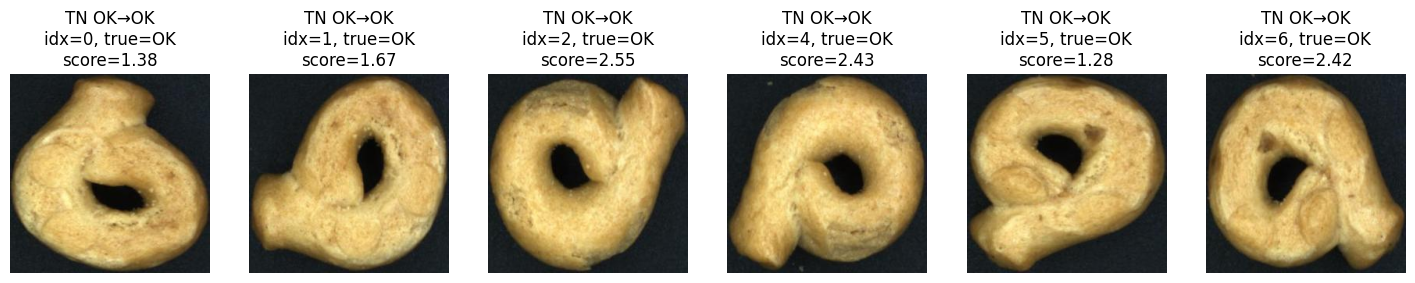

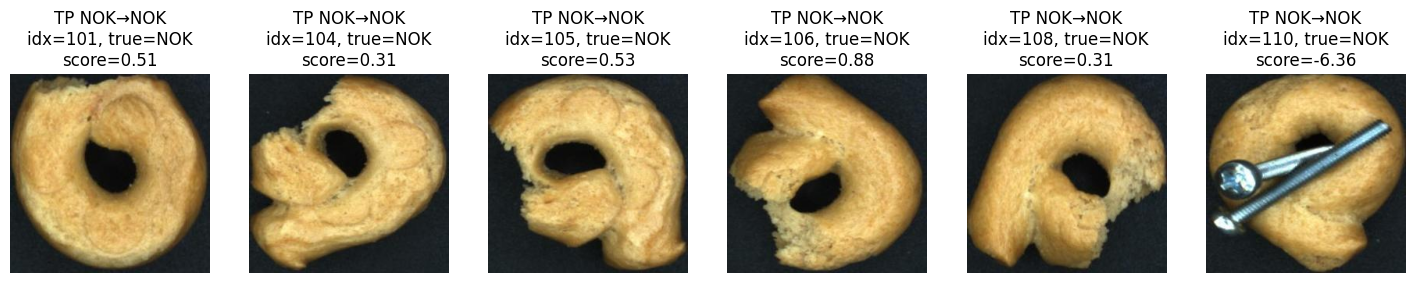

In [ ]:
show_samples(TN, "TN OK→OK", n=6)
show_samples(TP, "TP NOK→NOK", n=6)
